# Tripwire Surveillance: Restricted Region Entry Alarm

**Semester computer vision project — recorded footage demonstration**

**Objective:** detect a person entering a predefined region, turn the display red,
and send a Telegram alarm to a phone.

**Flow:** video → YOLO person detection → ByteTrack IDs → region entry check → alarm.

Run the cells from top to bottom in Google Colab (GPU recommended, CPU works too)
or a Python 3.10+ Jupyter notebook. Internet is needed for installation, downloads,
and Telegram. No training, webcam, separate scripts, or additional submission files.

**Phone demo:** set `SEND_TELEGRAM = True` in section 3 and enter your private
details when prompted. The saved example uses Telegram OFF. Notifications are sent
**during processing**, when the live preview crosses the boundary; replaying the
finished video does not send them again.

## 1. Install and import

YOLO11n uses pretrained COCO weights; we keep only the **person** class.
ByteTrack links detections across frames, so one person does not generate an
alarm on every frame. Package versions below are fixed for this lab.

In [1]:
%pip -q install ultralytics==8.3.225 opencv-python==4.11.0.86 lap==0.5.12 imageio-ffmpeg==0.6.0

import os
import time
import getpass
import subprocess
from pathlib import Path

WORK = Path("tripwire_runtime")
WORK.mkdir(exist_ok=True)
(WORK / "settings" / "Ultralytics").mkdir(parents=True, exist_ok=True)
os.environ["YOLO_CONFIG_DIR"] = str((WORK / "settings").resolve())
os.environ["YOLO_AUTOINSTALL"] = "false"

import cv2
import numpy as np
import requests
import torch
import matplotlib.pyplot as plt
import imageio_ffmpeg
from ultralytics import YOLO
from IPython.display import display, HTML, Image, Video

torch.set_num_threads(2)  # Keeps the small model responsive on CPU laptops.
DEVICE = 0 if torch.cuda.is_available() else "cpu"
print(f"Ready. Processing device: {DEVICE}")

Ready. Processing device: cpu


## 2. Load the footage and mark the region

We download Roboflow's public **people-walking** example and use its first
**10 seconds**. All frames are resized to **960 × 540**; the four region points
below refer to that size. The preview shows exactly what will be monitored.

For your own footage later, change `VIDEO_PATH` to its uploaded filename and
adjust `REGION` using the preview axes. Leave the defaults for this demonstration.

**Optional downloaded demos:** the project also includes three prepared 10-second,
25 FPS videos. Upload a chosen file to Colab, or use its `demo_videos/` path locally.
Replace only the existing `VIDEO_PATH` and `REGION` assignments below:

| File | Region points (960 × 540) | Tested entry count |
| --- | --- | --- |
| `01_worker_zone_25fps.mp4` (recommended) | `[[440,300],[720,300],[720,450],[440,450]]` | 1 |
| `02_indoor_entry_25fps.mp4` | `[[560,300],[880,300],[880,430],[560,430]]` | 1 |
| `03_crowd_25fps.mp4` | `[[400,350],[560,350],[560,430],[400,430]]` | 4 |

For example, use `VIDEO_PATH = Path("01_worker_zone_25fps.mp4")` and
`REGION = np.array([[440,300],[720,300],[720,450],[440,450]], dtype=np.int32)`
for the uploaded worker clip. Leave `MAX_SECONDS = 10`.
These optional files are for trying additional footage; they are not required
for the default run or notebook-only submission. Worker and indoor originals
come from [Intel sample videos](https://github.com/intel-iot-devkit/sample-videos)
([CC BY 4.0](https://github.com/intel-iot-devkit/sample-videos/blob/master/LICENSE));
the copies were trimmed, resized, and converted from approximately 59.94 and
12 FPS respectively to 25 FPS. The crowd source is Roboflow's original 25 FPS
example. Conversion of the indoor video repeats frames, adding no new motion detail.


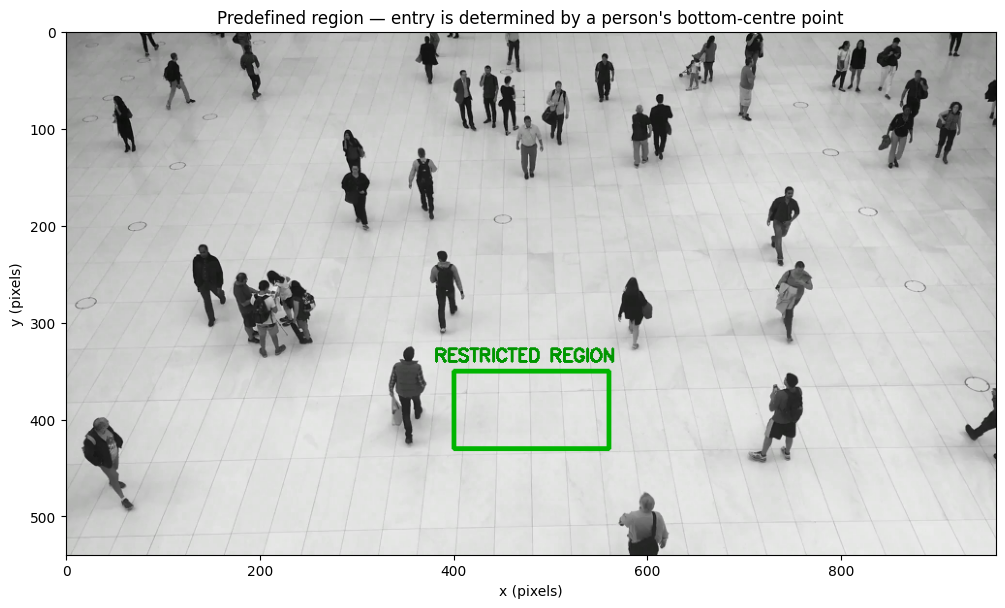

Video: 25 FPS | monitoring the first 10 seconds


In [2]:
VIDEO_URL = "https://media.roboflow.com/supervision/video-examples/people-walking.mp4"
VIDEO_PATH = WORK / "people-walking.mp4"
FRAME_SIZE = (960, 540)
MAX_SECONDS = 10
REGION = np.array([[400, 350], [560, 350], [560, 430], [400, 430]], dtype=np.int32)
CONFIRM_FRAMES = 3

def download(url, path):
    if not path.exists():
        response = requests.get(url, timeout=120)
        response.raise_for_status()
        path.write_bytes(response.content)

download(VIDEO_URL, WORK / "people-walking.mp4")
cap = cv2.VideoCapture(str(VIDEO_PATH))
ok, first_frame = cap.read()
FPS = cap.get(cv2.CAP_PROP_FPS)
cap.release()
if not ok or FPS <= 0:
    raise RuntimeError("Cannot read the video. Check the download or VIDEO_PATH.")

first_frame = cv2.resize(first_frame, FRAME_SIZE)
preview_frame = first_frame.copy()
cv2.polylines(preview_frame, [REGION], True, (0, 180, 0), 3)
cv2.putText(preview_frame, "RESTRICTED REGION", (380, 340),
            cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 150, 0), 2)
plt.figure(figsize=(12, 7))
plt.imshow(cv2.cvtColor(preview_frame, cv2.COLOR_BGR2RGB))
plt.title("Predefined region — entry is determined by a person's bottom-centre point")
plt.xlabel("x (pixels)")
plt.ylabel("y (pixels)")
plt.show()
print(f"Video: {FPS:g} FPS | monitoring the first {MAX_SECONDS} seconds")

## 3. Phone notification (Telegram)

To include the phone notification in your demonstration:

1. In Telegram, open the official **@BotFather**, send `/newbot`, and follow its
   instructions. Copy the bot token.
2. Open **your new bot** and press **Start** or send it a message.
3. Set `SEND_TELEGRAM = True` below. Paste the token into the hidden prompt.
   The notebook reads the latest private conversation to find your chat ID.

Use a fresh personal demo bot and message it only from your own account.
Telegram OFF lets you run the visual demonstration without an account.
Tokens and chat IDs are never printed or written into this notebook.

In [3]:
SEND_TELEGRAM = False  # Change to True for the phone-notification demonstration.
bot_token = ""
chat_id = ""

if SEND_TELEGRAM:
    bot_token = getpass.getpass("BotFather token (hidden): ").strip()
    try:
        reply = requests.get(
            f"https://api.telegram.org/bot{bot_token}/getUpdates", timeout=15
        ).json()
        chats = [u["message"]["chat"]["id"] for u in reply.get("result", [])
                 if u.get("message", {}).get("chat", {}).get("type") == "private"]
        if reply.get("ok") and chats:
            chat_id = str(chats[-1])
            print("Private chat found. Phone alarms are enabled.")
        else:
            print("Chat not found. Check the token, message your bot, then rerun this cell.")
    except (requests.RequestException, ValueError):
        print("Telegram could not be reached. Check your internet and rerun this cell.")
else:
    print("Telegram OFF. Red visual alarms and the event table still work.")

def send_alarm(message):
    if not SEND_TELEGRAM:
        return "OFF"
    if not bot_token or not chat_id:
        return "NOT CONFIGURED"
    try:
        reply = requests.post(
            f"https://api.telegram.org/bot{bot_token}/sendMessage",
            json={"chat_id": chat_id, "text": message}, timeout=8
        )
        if reply.status_code == 200 and reply.json().get("ok"):
            return "SENT"
        return "FAILED (check bot/chat)"
    except (requests.RequestException, ValueError):
        return "FAILED (network)"

Telegram OFF. Red visual alarms and the event table still work.


## 4. Detect people and decide when an entry happens

**Geometry:** the bottom-centre of a person's box approximates their position
on the floor. OpenCV tests whether this point is inside the polygon.

**Alarm rule:** first observe a tracked person outside for 3 consecutive frames
to arm their alarm. Then 3 consecutive inside frames confirm entry. Remaining
inside produces no further alerts. A confirmed exit rearms that person's alarm.
At 25 FPS, 3 frames span approximately 0.12 seconds.

A person first detected inside is shown in red but does not count as an observed
entry until they leave and enter again. Missing detections reset the confirmation
streaks. Track IDs are temporary labels, not face recognition.

In [4]:
MODEL_PATH = WORK / "yolo11n.pt"
download("https://github.com/ultralytics/assets/releases/download/v8.3.0/yolo11n.pt",
         MODEL_PATH)

def update_zone(state, inside):
    state["in_count"] = state["in_count"] + 1 if inside else 0
    state["out_count"] = 0 if inside else state["out_count"] + 1
    if state["out_count"] >= CONFIRM_FRAMES:
        state["inside"] = False
        state["armed"] = True
    if state["in_count"] >= CONFIRM_FRAMES:
        state["inside"] = True
        if state["armed"]:
            state["armed"] = False
            return True
    return False

print("Pretrained weights ready. No model training is required.")

Pretrained weights ready. No model training is required.


## 5. Run the intrusion demonstration

Run this cell while holding your phone. The preview updates about once per video
second and immediately on an entry. Green means clear; red marks a confirmed
person in the region, with an **INTRUSION DETECTED** banner for entry events.

Processing may be faster or slower than playback. Each Telegram message includes
the **video timestamp**. Rerunning this cell starts a fresh demonstration and
sends its entry messages again when Telegram is enabled.

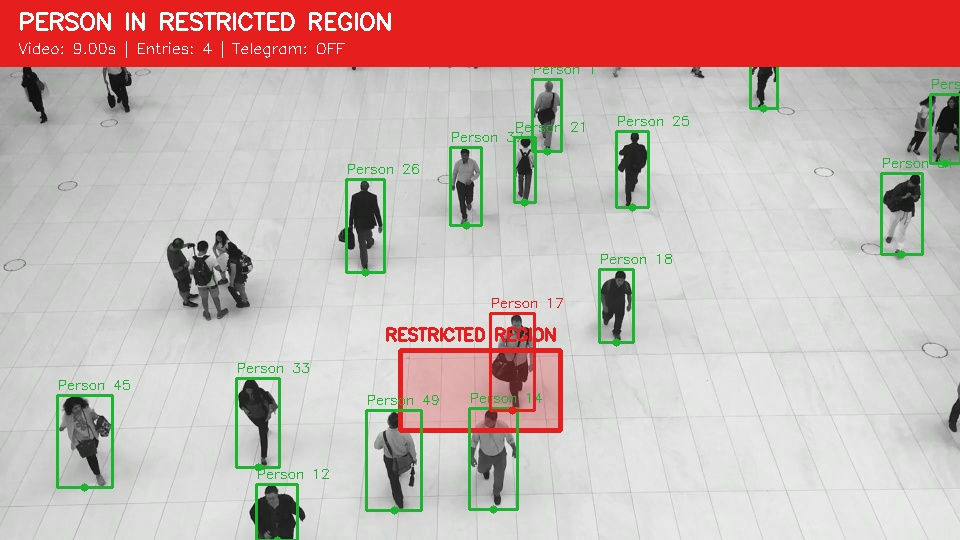

Processed 10.00s of footage in 27.8s.


In [5]:
model = YOLO(str(MODEL_PATH))  # Fresh tracker on every run.
cap = cv2.VideoCapture(str(VIDEO_PATH))
raw_video = WORK / "annotated_raw.mp4"
writer = cv2.VideoWriter(str(raw_video), cv2.VideoWriter_fourcc(*"mp4v"), FPS, FRAME_SIZE)
if not cap.isOpened() or not writer.isOpened():
    cap.release()
    writer.release()
    raise RuntimeError("Could not open the video reader/writer. Rerun setup and try again.")

states, events = {}, []
alarm_frame = None
alarm_until = -1
frame_index = 0
limit = int(MAX_SECONDS * FPS)
started = time.perf_counter()
live = display(Image(data=cv2.imencode(".jpg", preview_frame)[1].tobytes()), display_id=True)
progress = display(HTML("Processing footage…"), display_id=True)

try:
    while frame_index < limit:
        ok, frame = cap.read()
        if not ok:
            break
        frame = cv2.resize(frame, FRAME_SIZE)
        result = model.track(frame, persist=True, tracker="bytetrack.yaml",
                             classes=[0], conf=0.35, imgsz=640,
                             device=DEVICE, verbose=False)[0]
        seen, people = set(), []
        entry_now = False
        boxes = result.boxes
        if boxes.id is not None:
            for box, identity in zip(boxes.xyxy.tolist(), boxes.id.tolist()):
                person_id = int(identity)
                seen.add(person_id)
                x1, y1, x2, y2 = box
                point = ((x1 + x2) / 2, y2)
                inside = cv2.pointPolygonTest(REGION, point, False) >= 0
                state = states.setdefault(person_id, {
                    "inside": False, "armed": False, "in_count": 0, "out_count": 0
                })
                if update_zone(state, inside):
                    seconds = round(frame_index / FPS, 2)
                    message = (f"INTRUSION DETECTED! Person #{person_id} entered "
                               f"the restricted region at video time {seconds:.2f}s.")
                    delivery = send_alarm(message)
                    events.append({"Person ID": person_id, "Video time (s)": seconds,
                                   "Telegram": delivery})
                    entry_now = True
                    alarm_until = frame_index + int(FPS)
                people.append((box, point, person_id, state["inside"]))

        for person_id, state in states.items():
            if person_id not in seen:
                state["in_count"] = state["out_count"] = 0

        occupied = any(person[3] for person in people)
        alarm_visible = frame_index <= alarm_until
        red_display = occupied or alarm_visible
        zone_color = (30, 30, 230) if red_display else (50, 180, 30)
        tint = frame.copy()
        cv2.fillPoly(tint, [REGION], zone_color)
        frame = cv2.addWeighted(tint, 0.25, frame, 0.75, 0)
        cv2.polylines(frame, [REGION], True, zone_color, 3)
        cv2.putText(frame, "RESTRICTED REGION", (385, 340),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.55, zone_color, 2)
        for box, point, person_id, in_zone in people:
            x1, y1, x2, y2 = map(int, box)
            color = (30, 30, 230) if in_zone else (50, 180, 30)
            cv2.rectangle(frame, (x1, y1), (x2, y2), color, 2)
            cv2.circle(frame, tuple(map(int, point)), 4, color, -1)
            cv2.putText(frame, f"Person {person_id}", (x1, max(18, y1 - 6)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.45, color, 1)

        title = ("INTRUSION DETECTED" if alarm_visible else
                 "PERSON IN RESTRICTED REGION" if occupied else "MONITORING - REGION CLEAR")
        cv2.rectangle(frame, (0, 0), (960, 66), zone_color if red_display else (35, 45, 35), -1)
        cv2.putText(frame, title, (18, 29), cv2.FONT_HERSHEY_SIMPLEX, 0.75, (255, 255, 255), 2)
        delivery = events[-1]["Telegram"] if events else ("READY" if chat_id else "OFF")
        detail = f"Video: {frame_index / FPS:.2f}s | Entries: {len(events)} | Telegram: {delivery}"
        cv2.putText(frame, detail, (18, 53), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1)
        writer.write(frame)
        if entry_now and alarm_frame is None:
            alarm_frame = frame.copy()
        if frame_index % max(1, round(FPS)) == 0 or entry_now:
            live.update(Image(data=cv2.imencode(".jpg", frame)[1].tobytes()))
            progress.update(HTML(f"Processed {frame_index / FPS:.1f}s — entry events: {len(events)}"))
        frame_index += 1
finally:
    cap.release()
    writer.release()

elapsed = time.perf_counter() - started
progress.update(HTML(f"<b>Complete:</b> {frame_index} frames, {len(events)} entry events. See playback below."))
print(f"Processed {frame_index / FPS:.2f}s of footage in {elapsed:.1f}s.")

## 6. Watch the result inside the notebook

We convert the generated video to browser-compatible H.264 and embed it in this
notebook. Saving the notebook retains the player and result snapshot; the runtime
video files do not need to be submitted separately. Press **Play** below.

First confirmed entry:


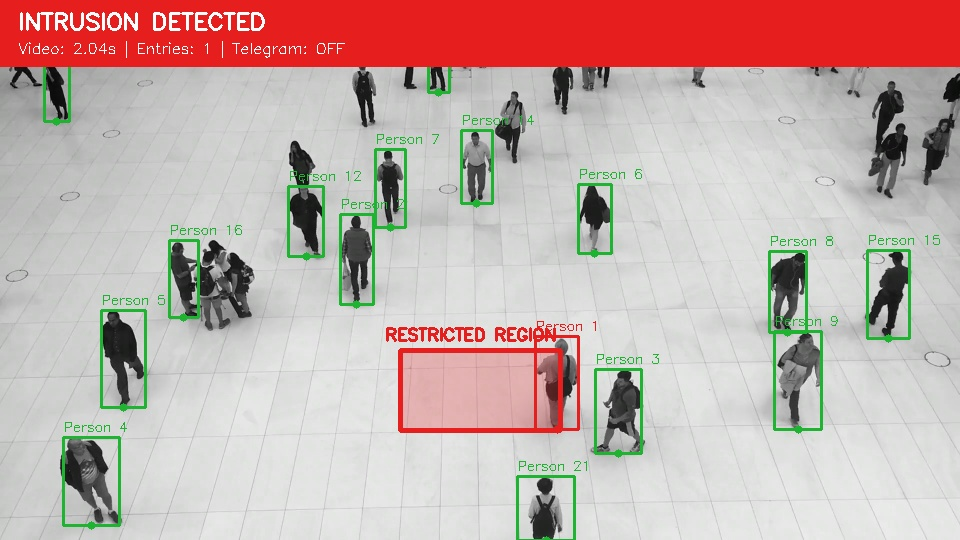

In [6]:
output_video = WORK / "tripwire_result.mp4"
command = [imageio_ffmpeg.get_ffmpeg_exe(), "-y", "-loglevel", "error",
           "-i", str(raw_video), "-c:v", "libx264", "-preset", "fast",
           "-crf", "23", "-pix_fmt", "yuv420p", "-movflags", "+faststart",
           "-an", str(output_video)]
conversion = subprocess.run(command, capture_output=True, text=True)
if conversion.returncode:
    raise RuntimeError("Video conversion failed: " + conversion.stderr[-500:])

display(Video(filename=str(output_video), embed=True, width=960,
              html_attributes="controls playsinline"))
if alarm_frame is not None:
    print("First confirmed entry:")
    display(Image(data=cv2.imencode(".jpg", alarm_frame)[1].tobytes(), width=960))
else:
    print("No confirmed entry was found for this region and footage.")

## 7. Results and brief evaluation

The table contains **entry events**, not every frame with a person inside. `SENT`
means Telegram accepted the request; verify arrival on your phone. `OFF` means
delivery was disabled, and a failure status must not be presented as a sent alarm.

**Check the demonstration:** watch an entry at a listed timestamp, observe the
red display, and verify that remaining inside does not repeatedly add rows.
The default clip should show a clear interval before the first entry.

In [7]:
from html import escape

if events:
    rows = "".join(
        f"<tr><td>{e['Person ID']}</td><td>{e['Video time (s)']:.2f}</td>"
        f"<td>{escape(e['Telegram'])}</td></tr>" for e in events
    )
    display(HTML("<table><tr><th>Person ID</th><th>Video time (s)</th>"
                 "<th>Telegram</th></tr>" + rows + "</table>"))
print(f"Total confirmed entries: {len(events)}")
print(f"Processing rate: {frame_index / elapsed:.1f} FPS (includes display and notification time)")
print(f"Telegram: {'enabled' if SEND_TELEGRAM else 'OFF in this run'}")

Person ID,Video time (s),Telegram
1,2.04,OFF
21,4.12,OFF
14,6.28,OFF
17,7.96,OFF


Total confirmed entries: 4
Processing rate: 9.0 FPS (includes display and notification time)
Telegram: OFF in this run


### Explanation, limitations, and references

This project combines a learned detector with tracking and a geometric entry
rule. **No custom training or intrusion-labelled dataset is needed.** The
restricted region is defined by us, and the alarm condition is programmed.

This is a short recorded-footage demonstration, not a measured real-time CCTV
deployment. Tiny or hidden people may be missed. ID changes can cause missed or
duplicate entries; three-frame confirmation reduces jitter but cannot guarantee
correctness. The bottom-centre is an approximation, and the region must be
adjusted if the camera view changes. No accuracy percentage is claimed from
this one demonstration.

- [YOLO11 pretrained detector](https://docs.ultralytics.com/models/yolo11/)
- [ByteTrack through Ultralytics](https://docs.ultralytics.com/modes/track/)
- [Roboflow Supervision public example footage](https://supervision.roboflow.com/0.28.0/assets/)
  (`people-walking.mp4`; video is downloaded from the publisher, not supplied as original work)
- [Telegram Bot API](https://core.telegram.org/bots/api#sendmessage)

**Submission:** save/download this `.ipynb` with outputs. Only the notebook is
required; installation and download cells reconstruct its runtime files.